# 05 · Fluid Benchmarking results

Results of `scripts/irt/adaptive_run_experiment.py`, adapted from Fluid Benchmarking (Hofmann et al., 2025).

**Idea:** instead of a fixed set of questions, Fluid asks each model one question at a time. It always picks the question that tells it most about the model's ability θ at the current estimate.

**Setup**
- Each test model is asked up to k questions, for k = 10, 20, 50, 100, 200, 500.
- **5 splits**: the test models change each time, and no test model has a close relative in train

**Methods compared**
| method | how θ is estimated |
|---|---|
| fluid | from k questions chosen adaptively (one run per model) |
| random_ability | from k random questions (20 seeds) |

**Reference values**
- **true θ** = θ estimated from all MMLU questions (14,042 questions).
- **true accuracy** = the model's real score on MMLU.

See key takeaways at the end of notebook

In [8]:
import sys

sys.path.insert(0, "../scripts/irt")  # for the efficbench loader

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from efficbench import load

from cabench.splits import behaviour_families, split_models

RESULTS = "../results/irt/mmlu_efficbench/"
metrics = pd.read_csv(RESULTS + "adaptive_test.csv") # error metrics per (split, k, method, seed, scale)
thetas = pd.read_csv(RESULTS + "adaptive_thetas.csv") # each test model's theta per (split, k, method, seed)
items_asked = pd.read_csv(RESULTS + "adaptive_items.csv") # every question Fluid asked, in order

METHODS = ["fluid", "random_ability"]
SCALES = ["ability", "accuracy"]
METRICS = ["mae", "rmse", "bias", "spearman"]

# Overview

## The splits
Models are grouped into families of similar models, and each family goes entirely into train, validation or test.
The splits are rebuilt here exactly as the script builds them. **matches results** checks that the test models are the same as the ones in the results.

Validation models are not used by Fluid; they only exist to keep the splits identical to the static experiment.

In [9]:
# Number of models in each split
Y, models, items = load()
print(f"{Y.shape[0]} models, {Y.shape[1]} questions, {items.subject.nunique()} subjects")

families = behaviour_families(Y, 0.3) # same FAMILY_DIST as adaptive_run_experiment.py
rows = []
for split in range(5):
    train, val, test_models = split_models(len(Y), split, groups=families)
    in_results = set(thetas[thetas.split == split].model_idx)
    rows.append({
        "split": split,
        "train": len(train),
        "val": len(val),
        "test": len(test_models),
        "matches results": in_results == set(test_models),
    })

pd.DataFrame(rows).set_index("split")

428 models, 14042 questions, 57 subjects


,train,val,test,matches results
split,,,,
0,303,60,65,True
1,300,64,64,True
2,303,60,65,True
3,293,71,64,True
4,300,82,46,True


# Main results

## 1. Error vs k

**Two scales**
- **ability**: estimated θ vs true θ.
- **accuracy**: θ converted to a predicted MMLU score, vs the real score. Use this scale to compare with the static methods.

**Metrics**
- MAE
- RMSE
- Bias
- Spearman - does the method rank the models in the right order? (1 = perfect)

In [10]:
runs = metrics[metrics.method != "full ability"]
floor = metrics[metrics.method == "full ability"] # theta from all 14,042 questions: the best this IRT model can do

# Average over seeds within each split, then mean ± sd across the 5 splits.
# Fluid has one run per split, so its "average over seeds" is that single run.
per_split = runs.groupby(["scale", "method", "k", "split"])[METRICS].mean()
summary = per_split.groupby(["scale", "method", "k"]).agg(["mean", "std"])


def mean_plus_minus_sd(scale, metric, number_format):
    """Table of "mean ± sd" strings: one row per k, one column per method."""
    stats = summary.loc[scale][metric]
    mean = stats["mean"].map(number_format.format)
    sd = stats["std"].map(number_format.format)
    return (mean + " ± " + sd).unstack("method")[METHODS]


FORMATS = {"ability": "{:.3f}", "accuracy": "{:.2%}"}
for scale in SCALES:
    print(f"{scale} scale")
    display(pd.concat(
        {m: mean_plus_minus_sd(scale, m, "{:.3f}" if m == "spearman" else FORMATS[scale]) for m in METRICS},
        axis=1,
    ))

print("error floor (accuracy scale)")
floor.set_index("split")[METRICS]

ability scale


mae                          rmse                 \
method          fluid random_ability          fluid random_ability   
k                                                                    
10      0.178 ± 0.038  0.451 ± 0.093  0.242 ± 0.065  0.593 ± 0.127   
20      0.145 ± 0.041  0.359 ± 0.073  0.201 ± 0.081  0.477 ± 0.103   
50      0.138 ± 0.071  0.239 ± 0.052  0.202 ± 0.137  0.324 ± 0.079   
100     0.134 ± 0.076  0.186 ± 0.046  0.201 ± 0.143  0.260 ± 0.075   
200     0.119 ± 0.072  0.124 ± 0.026  0.190 ± 0.139  0.172 ± 0.041   
500     0.105 ± 0.065  0.082 ± 0.019  0.173 ± 0.125  0.115 ± 0.031   

                 bias                       spearman                 
method          fluid  random_ability          fluid random_ability  
k                                                                    
10      0.008 ± 0.064  -0.023 ± 0.120  0.951 ± 0.014  0.747 ± 0.056  
20      0.018 ± 0.055  -0.023 ± 0.079  0.959 ± 0.012  0.840 ± 0.047  
50      0.038 ± 0.083  -0.032 ± 0.059  0.971 ± 0.017  0.924 ± 0.030  
100     0.044 ± 0.085  -0.024 ± 0.046  0.975 ± 0.016  0.949 ± 0.015  
200     0.046 ± 0.079  -0.016 ± 0.028  0.980 ± 0.013  0.966 ± 0.015  
500     0.045 ± 0.062  -0.010 ± 0.017  0.987 ± 0.008  0.983 ± 0.008

accuracy scale


mae                          rmse                 \
method          fluid random_ability          fluid random_ability   
k                                                                    
10      3.06% ± 0.47%  5.92% ± 0.81%  4.14% ± 0.46%  7.55% ± 0.95%   
20      2.67% ± 0.53%  4.59% ± 0.46%  3.65% ± 0.67%  5.77% ± 0.55%   
50      2.37% ± 0.45%  3.24% ± 0.46%  3.21% ± 0.73%  4.10% ± 0.60%   
100     2.29% ± 0.44%  2.62% ± 0.46%  3.03% ± 0.73%  3.38% ± 0.66%   
200     2.13% ± 0.42%  2.01% ± 0.48%  2.82% ± 0.73%  2.67% ± 0.68%   
500     1.94% ± 0.46%  1.69% ± 0.53%  2.56% ± 0.72%  2.29% ± 0.76%   

                  bias                       spearman                 
method           fluid  random_ability          fluid random_ability  
k                                                                     
10      -0.32% ± 1.06%   0.01% ± 0.92%  0.941 ± 0.013  0.744 ± 0.056  
20      -0.66% ± 1.00%  -0.29% ± 0.62%  0.948 ± 0.007  0.838 ± 0.046  
50      -0.73% ± 1.04%  -0.72% ± 0.62%  0.957 ± 0.016  0.918 ± 0.026  
100     -0.72% ± 1.05%  -0.74% ± 0.73%  0.961 ± 0.018  0.943 ± 0.012  
200     -0.74% ± 1.06%  -0.74% ± 0.72%  0.965 ± 0.018  0.959 ± 0.013  
500     -0.77% ± 0.96%  -0.75% ± 0.83%  0.973 ± 0.015  0.972 ± 0.014

error floor (accuracy scale)


,mae,rmse,bias,spearman
split,,,,
0,0.021818,0.026789,-0.014384,0.987991
1,0.015167,0.022492,-0.011917,0.965738
2,0.009463,0.010850,0.003902,0.994537
3,0.005579,0.007545,-0.003269,0.996783
4,0.013600,0.024433,-0.011251,0.988406


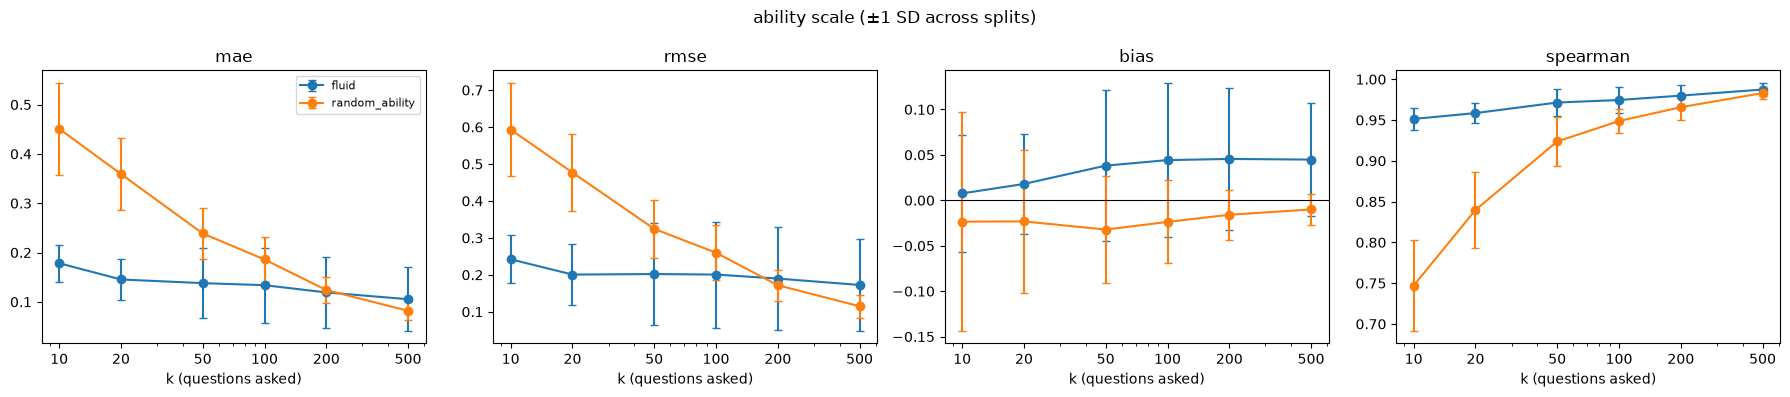

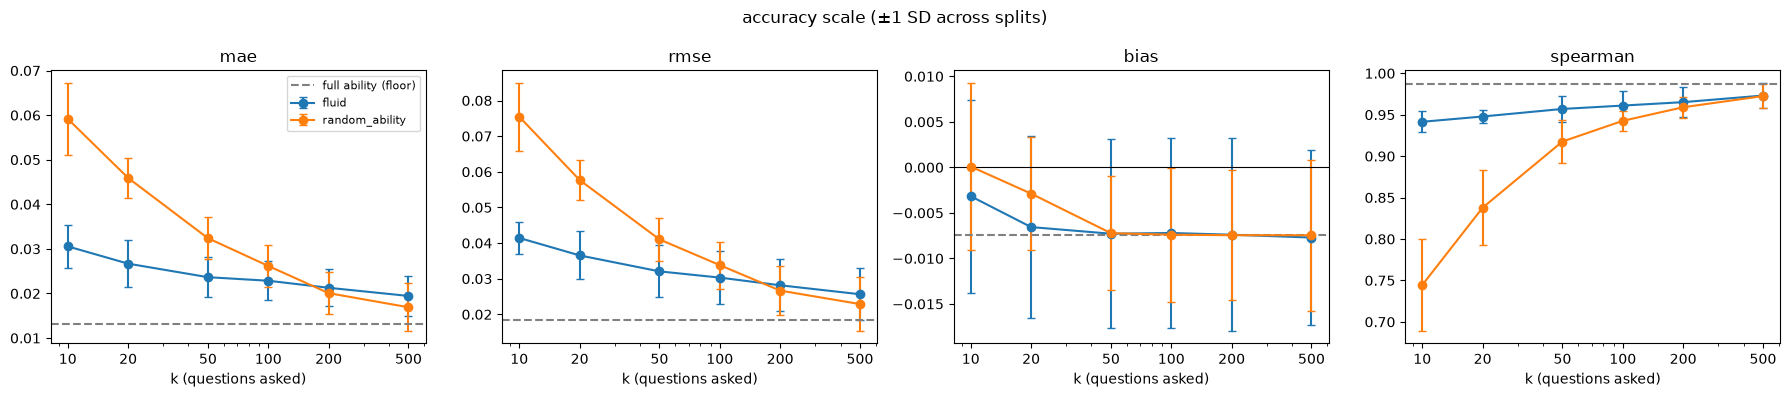

In [5]:
k_values = sorted(runs.k.unique())

for scale in SCALES:
    fig, axes = plt.subplots(1, 4, figsize=(18, 4))
    for ax, metric in zip(axes, METRICS):
        for method in METHODS:
            stats = summary.loc[(scale, method)][metric]  # one row per k
            ax.errorbar(stats.index, stats["mean"], yerr=stats["std"], marker="o", capsize=3, label=method)
        if scale == "accuracy":
            ax.axhline(floor[metric].mean(), color="grey", ls="--", label="full ability (floor)")
        if metric == "bias":
            ax.axhline(0, color="black", lw=0.8)
        ax.set(xscale="log", xlabel="k (questions asked)", title=metric)
        ax.set_xticks(k_values, k_values)
    axes[0].legend(fontsize=8)
    fig.suptitle(f"{scale} scale (±1 SD across splits)")
    plt.tight_layout()


## 2. How many random questions do you need to ask to match Fluid's error

In [ ]:
def random_k_for_same_error(scale):
    """For each Fluid k, the k at which random_ability reaches the same MAE (interpolated on log k)
    """
    mae = summary.loc[scale]["mae"]["mean"].unstack("method")
    k = mae.index.values
    assert (np.diff(mae.random_ability) < 0).all()  # interpolation needs random's MAE to fall with k
    # np.interp needs increasing x, so use -log(MAE). NaN = outside the k range that was run
    k_random = np.exp(np.interp(-np.log(mae.fluid), -np.log(mae.random_ability), np.log(k),
                                left=np.nan, right=np.nan))
    return pd.DataFrame({
        "fluid MAE": mae.fluid,
        "random k for same MAE": k_random.round(),
        "times fewer questions": (k_random / k).round(1),
    })


for scale in SCALES:
    print(f"{scale} scale")
    display(random_k_for_same_error(scale))


ability scale


,fluid MAE,random k for same MAE,times fewer questions
k,,,
10,0.178296,107.0,10.7
20,0.145385,152.0,7.6
50,0.137955,167.0,3.3
100,0.133831,175.0,1.8
200,0.119077,219.0,1.1
500,0.105343,286.0,0.6


accuracy scale


,fluid MAE,random k for same MAE,times fewer questions
k,,,
10,0.030562,60.0,6.0
20,0.026686,94.0,4.7
50,0.023652,130.0,2.6
100,0.022854,143.0,1.4
200,0.021273,172.0,0.9
500,0.019445,237.0,0.5


## 3. Theta basic stats

In [ ]:
# Estimates, pooled over all splits and k
display(thetas.groupby("method")[["theta", "expected_accuracy"]].describe().T.round(3))

# Reference values
reference = thetas[(thetas.method == "fluid") & (thetas.k == 500)] # 500 is an arbitrary choice - true estimates are constant across all k budgets 
reference[["true_theta", "true_accuracy"]].describe().round(3)

method                      fluid  random_ability
theta             count  1824.000       36480.000
                  mean     -0.134          -0.194
                  std       1.063           0.861
                  min      -2.226          -2.767
                  25%      -0.792          -0.776
                  50%      -0.302          -0.247
                  75%       0.415           0.325
                  max       4.000           3.165
expected_accuracy count  1824.000       36480.000
                  mean      0.541           0.542
                  std       0.127           0.118
                  min       0.202           0.147
                  25%       0.466           0.476
                  50%       0.552           0.562
                  75%       0.638           0.630
                  max       0.794           0.787

,true_theta,true_accuracy
count,304.000,304.000
mean,-0.168,0.547
std,0.968,0.120
min,-1.928,0.252
25%,-0.815,0.491
50%,-0.303,0.561
75%,0.354,0.621
max,2.695,0.786


## 4. Questions asked stats

In [23]:
# How many unique questions asked (overall and per split)?

n_runs = items_asked.groupby(["split", "model_idx"]).ngroups  # one Fluid run per (split, test model)
n_unique = items_asked.item_idx.nunique()
print(f"{n_unique} of {Y.shape[1]} questions asked at least once ({n_unique / Y.shape[1]:.0%})")
items_asked.groupby("split").item_idx.nunique().rename("unique questions")

4190 of 14042 questions asked at least once (30%)


split
0    3077
1    2557
2    2638
3    2872
4    2396
Name: unique questions, dtype: int64

,share of asked,share of MMLU,ratio
subject,,,
high_school_mathematics,0.004118,0.019228,0.214188
global_facts,0.001921,0.007121,0.269754
college_mathematics,0.002480,0.007121,0.348279
formal_logic,0.003414,0.008973,0.380524
machine_learning,0.003191,0.007976,0.400045
electrical_engineering,0.004572,0.010326,0.442794
virology,0.005270,0.011822,0.445769
high_school_physics,0.005020,0.010753,0.466802
moral_scenarios,0.031789,0.063737,0.498757


,share of asked,share of MMLU,ratio
subject,,,
prehistory,0.032941,0.023074,1.427638
high_school_microeconomics,0.024908,0.016949,1.469566
high_school_psychology,0.057145,0.038812,1.472342
clinical_knowledge,0.028263,0.018872,1.497627
college_medicine,0.019066,0.012320,1.547525
logical_fallacies,0.018026,0.011608,1.552917
high_school_geography,0.025757,0.014101,1.826636
high_school_government_and_politics,0.025730,0.013744,1.872043
astronomy,0.020901,0.010825,1.930897


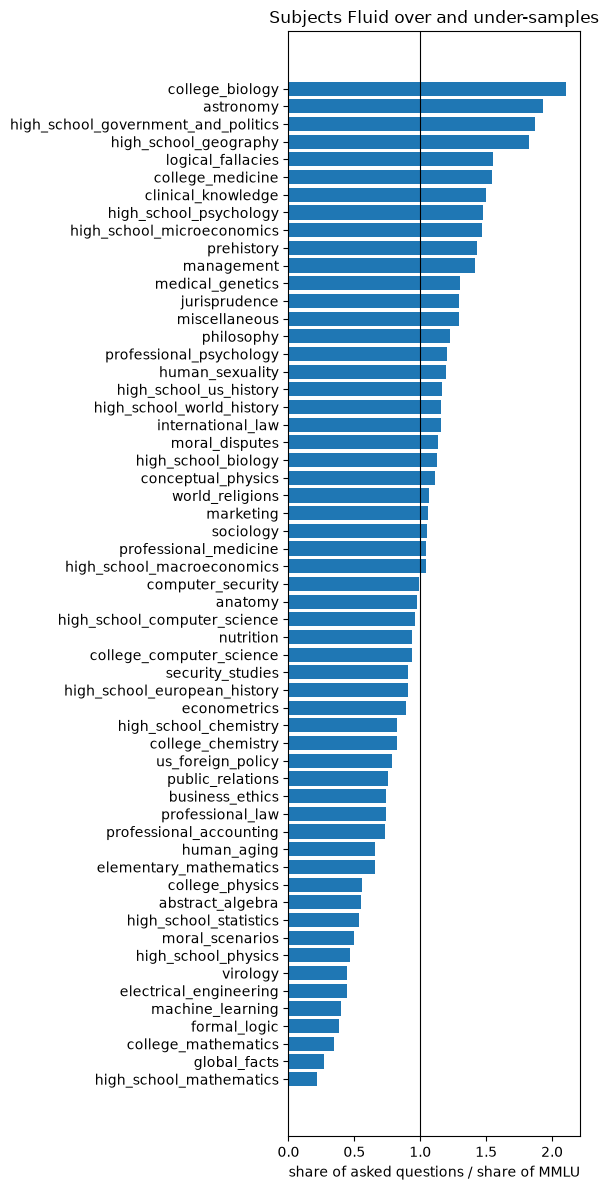

In [28]:
# Share of each subject among asked questions vs in MMLU. ratio > 1 = Fluid asks it more than its size suggests

subjects = pd.DataFrame({
    "share of asked": items_asked.subject.value_counts(normalize=True),
    "share of MMLU": items.subject.value_counts(normalize=True),
}).fillna(0)
subjects["ratio"] = subjects["share of asked"] / subjects["share of MMLU"]
subjects = subjects.sort_values("ratio")

fig, ax = plt.subplots(figsize=(6, 12))
ax.barh(subjects.index, subjects.ratio)
ax.axvline(1, color="black", lw=0.8)
ax.set(xlabel="share of asked questions / share of MMLU", title="Subjects Fluid over and under-samples")
plt.tight_layout()

display(subjects.head(10), subjects.tail(10))


In [22]:
# The first question depends only on the start ability, so it should be one question per split
items_asked[items_asked.step == 1].groupby("split").agg(
    first_question=("item_id", "unique"), a=("a", "first"), b=("b", "first")
)

,first_question,a,b
split,,,
0,[clinical_knowledge_17],4.026573,-0.034978
1,[medical_genetics_22],4.594699,-0.111288
2,[professional_law_1330],4.639276,-0.056174
3,[professional_accounting_92],4.289899,-0.104984
4,[astronomy_87],4.720246,-0.170276


In [24]:
# Most-asked questions. share of runs = fraction of all Fluid runs (all splits) that asked it
most_asked = (
    items_asked.groupby(["item_id", "subject"])
    .agg(times_asked=("step", "size"), mean_step=("step", "mean"), a=("a", "mean"), b=("b", "mean"))
    .sort_values("times_asked", ascending=False)
)
most_asked["share of runs"] = most_asked.times_asked / n_runs
most_asked.head(20).round(2)


,,times_asked,mean_step,a,b,share of runs
item_id,subject,,,,,
clinical_knowledge_17,clinical_knowledge,193,62.91,3.95,0.03,0.63
professional_accounting_92,professional_accounting,188,88.32,3.86,-0.19,0.62
astronomy_87,astronomy,186,41.70,4.25,-0.09,0.61
professional_law_1330,professional_law,174,37.99,4.47,-0.15,0.57
astronomy_30,astronomy,171,55.83,4.80,-0.31,0.56
high_school_geography_128,high_school_geography,164,33.66,5.59,-0.64,0.54
medical_genetics_22,medical_genetics,164,76.78,3.72,0.03,0.54
high_school_biology_128,high_school_biology,162,107.84,4.03,-0.46,0.53
college_computer_science_90,college_computer_science,162,154.37,3.26,-0.10,0.53


# Key Takeaways

**Fluid is much better with few questions**
- At k = 10, Fluid's accuracy error is 3.1% vs 5.9% for random questions.
- To match Fluid at k = 10, random needs about 60 questions on the accuracy scale (6x more) and about 107 on the ability scale (11x more).

**The advantage disappears at larger budgets**
- The methods are about the same at k = 200.
- At k = 500, random is better (1.7% vs 1.9% accuracy error).

**Fluid ranks models better at every budget**
- Spearman at k = 10: 0.94 vs 0.74. With 10 questions, Fluid already orders models about as well as random does with 100.

**Some error can't be removed by asking more questions**
- Even with all 14,042 questions, the predicted accuracy is off by 1.3% on average, because the IRT model isn't perfect.
- Fluid at k = 500 is off by 1.9%, so only about 0.6% of its error comes from asking too few questions, the rest is due to the IRT model

**Fluid uses a small, shared pool of questions**
- Only 30% of MMLU is ever asked: 2,400–3,100 questions per split.
- Every model in a split gets the same first question: very discriminating (a is roughly 4 - 4.7) and of medium difficulty (b is roughly 0).

**Fluid's question mix is skewed by subject**
- Maths and logic are asked much less than their share of MMLU (high-school maths about 0.2x).
- Knowledge subjects like biology, geography and politics are asked about 2x their share.
- So Fluid's score weights subjects differently from plain MMLU accuracy.
